# Churn Project
Kaitlyn Khrenovsky, Sam Bianco, Will Erne

Date: October 28, 2026

# Audience and Purpose

The audience for this project is the shared work practitioner, specifically data analysts or other team members who may need to reproduce, evaluate, or build on our work. Additionally, our analysis is intended for telecommunications managers and business leaders who are interested in understanding customer churn and identifying areas to improve customer retention.


The purpose of this project is to develop a workflow to identify factors associated with customer churn and predict which telecommunication customers are most likely to leave. Our analysis begins with cleaning and preparing the dataset, addressing any data quality issues. We then use exploratory data analysis, summary statistics, and visualizations to examine customer characteristics and identify patterns associated with churn. Through this analysis, we aim to provide meaningful insights into customers behavior and identify opportunities for telecommunications companies to improve customer retention.


# Computing Environment

This analysis was conducted in google colab. We used Python as our primary programming language, along with several libraries to clean and transform the data. The packages we used were, pandas, numpy, matplotlib, and seaborn

# Business Value Proposition

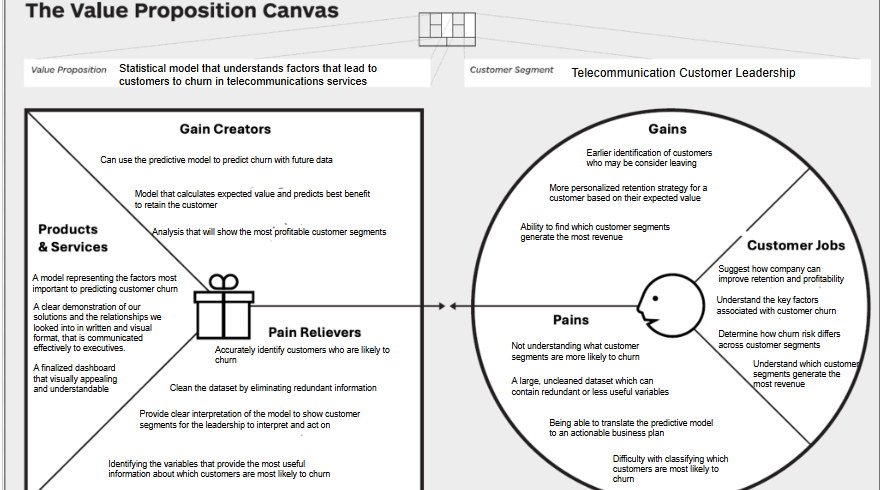

**Description of the Data**

The dataset contains 7,043 customer observations and 17 original variables from a telecommunications company. The variables include customer demographics, service subscriptions, contract information, payment methods, and customer behavior. The response variable is Churn, which indicates whether a customer has left the company (Yes) or remained with the company (No). Our analysis focuses on preparing these variables for predictive modeling by examining missing values, distributions, potential outliers, and relationships between variables. This preprocessing will help ensure the dataset is suitable for identifying factors associated with customer churn.

In [ ]:
# import packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
# read the data
df = pd.read_csv('https://raw.githubusercontent.com/khrenokg/Churn-Data/refs/heads/main/Churn_class_project%20(1).csv')
df.info()
display(df.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 17 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   customerID                 7043 non-null   object 
 1   gender                     7043 non-null   object 
 2   SeniorCitizen              7043 non-null   object 
 3   tenure                     6761 non-null   float64
 4   PhoneService               7043 non-null   object 
 5   MultipleLines              7043 non-null   object 
 6   InternetService            7043 non-null   object 
 7   TechSupport                7043 non-null   object 
 8   Contract                   7043 non-null   object 
 9   PaperlessBilling           7043 non-null   object 
 10  PaymentMethod              6761 non-null   object 
 11  CustomerAge                6973 non-null   float64
 12  AnnualIncome               6973 non-null   float64
 13  MonthlyCallMinutes         6973 non-null   float

,customerID,gender,SeniorCitizen,tenure,PhoneService,MultipleLines,InternetService,TechSupport,Contract,PaperlessBilling,PaymentMethod,CustomerAge,AnnualIncome,MonthlyCallMinutes,AveragePaymentDelayDays,CustomerSatisfactionScore,Churn
0,7590-VHVEG,Female,No,1.0,No,Yes,DSL,No,Month-to-month,No,Electronic check,77.0,39408.0,0.0,11.4,6.0,No
1,5575-GNVDE,Male,No,34.0,Yes,No,DSL,No,One year,Yes,Mailed check,22.0,102292.0,375.1,0.5,6.6,No
2,3668-QPYBK,Male,No,2.0,Yes,No phone service,DSL,No,Month-to-month,Yes,Mailed check,43.0,26869.0,373.6,3.4,6.2,Yes
3,7795-CFOCW,Male,No,45.0,No,Yes,DSL,Yes,One year,Yes,NaN,71.0,90565.0,0.0,1.4,6.8,No
4,9237-HQITU,Female,No,2.0,Yes,No,Fiber optic,No,Month-to-month,Yes,Electronic check,NaN,83510.0,221.7,5.8,6.3,Yes


In [ ]:
# descriptive statistics for all numeric columns
df.describe().T

,count,mean,std,min,25%,50%,75%,max
tenure,6761.0,32.441651,24.561694,0.0,9.0,29.0,56.0,72.0
CustomerAge,6973.0,46.689230,16.576262,18.0,35.0,44.0,57.0,90.0
AnnualIncome,6973.0,62124.351642,29417.754988,18000.0,41357.0,55841.0,76273.0,250000.0
MonthlyCallMinutes,6973.0,467.187079,226.335372,0.0,346.1,494.5,623.1,1161.5
AveragePaymentDelayDays,6973.0,3.325742,3.003101,0.0,1.2,2.5,4.5,24.0
CustomerSatisfactionScore,6973.0,6.859587,1.387753,1.5,5.9,6.9,7.8,10.0


In [ ]:
# descripitve statistics for all categorical columns
df.describe(include='object').T

,count,unique,top,freq
customerID,7043,7043,3186-AJIEK,1
gender,7043,2,Male,3555
SeniorCitizen,7043,2,No,5901
PhoneService,7043,2,Yes,6361
MultipleLines,7043,3,No,3390
InternetService,7043,3,Fiber optic,3096
TechSupport,7043,3,No,3473
Contract,7043,3,Month-to-month,3875
PaperlessBilling,7043,2,Yes,4171
PaymentMethod,6761,4,Electronic check,2260


In [ ]:
# checking for duplicates and found there is none
df.duplicated().sum()

np.int64(0)

In [ ]:
df.isna().any(axis=1).sum()

np.int64(877)

**Check for variables with mssing data and imputing the null values**

In [ ]:
# checking which variables have null
df.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
tenure,282
PhoneService,0
MultipleLines,0
InternetService,0
TechSupport,0
Contract,0
PaperlessBilling,0


When looking at the table of missing values throughout the dataset, we see that there are several fields that are missing quite a few values. Of these, there are many numeric fields (Tenure, AnnualIncome, MonthlyCallMinutes, CustomerAge, AveragePaymentDelay, and CustomerSatisfactionScore) that are missing values, as well as a few Categorical fields that are missing values (PaymentMethod).


In [ ]:
# impute the null values in PaymentMethod to say 'Missing'
df['PaymentMethod'] = df['PaymentMethod'].fillna('Missing')
df

,customerID,gender,SeniorCitizen,tenure,PhoneService,MultipleLines,InternetService,TechSupport,Contract,PaperlessBilling,PaymentMethod,CustomerAge,AnnualIncome,MonthlyCallMinutes,AveragePaymentDelayDays,CustomerSatisfactionScore,Churn
0,7590-VHVEG,Female,No,1.0,No,Yes,DSL,No,Month-to-month,No,Electronic check,77.0,39408.0,0.0,11.4,6.0,No
1,5575-GNVDE,Male,No,34.0,Yes,No,DSL,No,One year,Yes,Mailed check,22.0,102292.0,375.1,0.5,6.6,No
2,3668-QPYBK,Male,No,2.0,Yes,No phone service,DSL,No,Month-to-month,Yes,Mailed check,43.0,26869.0,373.6,3.4,6.2,Yes
3,7795-CFOCW,Male,No,45.0,No,Yes,DSL,Yes,One year,Yes,Missing,71.0,90565.0,0.0,1.4,6.8,No
4,9237-HQITU,Female,No,2.0,Yes,No,Fiber optic,No,Month-to-month,Yes,Electronic check,NaN,83510.0,221.7,5.8,6.3,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,6840-RESVB,Male,No,24.0,Yes,No,DSL,Yes,One year,No,Mailed check,72.0,33447.0,332.9,0.1,9.1,No
7039,2234-XADUH,Female,No,72.0,Yes,No,Fiber optic,No,One year,Yes,Credit card (automatic),46.0,58274.0,688.3,1.6,7.0,No
7040,4801-JZAZL,Female,No,11.0,No,Yes,DSL,No,Month-to-month,Yes,Electronic check,46.0,47462.0,0.0,4.6,6.4,No
7041,8361-LTMKD,Male,Yes,4.0,Yes,Yes,Fiber optic,No,Month-to-month,Yes,Mailed check,40.0,71378.0,550.2,6.7,5.7,Yes


In [ ]:
# Conduct median imputation for the null values in Annual Income, PaymenyDeleyDays, and CustomerAge
cols_to_impute2 = [
    'AnnualIncome',
    'AveragePaymentDelayDays',
    'CustomerAge',
]

# Impute missing values with the median for each specified column
for col in cols_to_impute2:
    if col in df.columns:
        df[col] = df[col].fillna(df[col].median())

# Verify that there are no remaining missing values in these columns
print(df[cols_to_impute2].isnull().sum())
display(df.head())

AnnualIncome               0
AveragePaymentDelayDays    0
CustomerAge                0
dtype: int64


,customerID,gender,SeniorCitizen,tenure,PhoneService,MultipleLines,InternetService,TechSupport,Contract,PaperlessBilling,PaymentMethod,CustomerAge,AnnualIncome,MonthlyCallMinutes,AveragePaymentDelayDays,CustomerSatisfactionScore,Churn
0,7590-VHVEG,Female,No,1.0,No,Yes,DSL,No,Month-to-month,No,Electronic check,77.0,39408.0,0.0,11.4,6.0,No
1,5575-GNVDE,Male,No,34.0,Yes,No,DSL,No,One year,Yes,Mailed check,22.0,102292.0,375.1,0.5,6.6,No
2,3668-QPYBK,Male,No,2.0,Yes,No phone service,DSL,No,Month-to-month,Yes,Mailed check,43.0,26869.0,373.6,3.4,6.2,Yes
3,7795-CFOCW,Male,No,45.0,No,Yes,DSL,Yes,One year,Yes,Missing,71.0,90565.0,0.0,1.4,6.8,No
4,9237-HQITU,Female,No,2.0,Yes,No,Fiber optic,No,Month-to-month,Yes,Electronic check,44.0,83510.0,221.7,5.8,6.3,Yes


In [ ]:
# Conduct mean imputation for the null values in tenure, MonthlyCallMinutes, and CustomerSatisfactionScore
cols_to_impute = [
    'tenure',
    'MonthlyCallMinutes',
    'CustomerSatisfactionScore'
]

# Impute missing values with the mean for each specified column
for col in cols_to_impute:
    if col in df.columns:
        df[col] = df[col].fillna(df[col].mean())

# Verify that there are no remaining missing values in these columns
print(df[cols_to_impute].isnull().sum())
display(df.head())

tenure                       0
MonthlyCallMinutes           0
CustomerSatisfactionScore    0
dtype: int64


,customerID,gender,SeniorCitizen,tenure,PhoneService,MultipleLines,InternetService,TechSupport,Contract,PaperlessBilling,PaymentMethod,CustomerAge,AnnualIncome,MonthlyCallMinutes,AveragePaymentDelayDays,CustomerSatisfactionScore,Churn
0,7590-VHVEG,Female,No,1.0,No,Yes,DSL,No,Month-to-month,No,Electronic check,77.0,39408.0,0.0,11.4,6.0,No
1,5575-GNVDE,Male,No,34.0,Yes,No,DSL,No,One year,Yes,Mailed check,22.0,102292.0,375.1,0.5,6.6,No
2,3668-QPYBK,Male,No,2.0,Yes,No phone service,DSL,No,Month-to-month,Yes,Mailed check,43.0,26869.0,373.6,3.4,6.2,Yes
3,7795-CFOCW,Male,No,45.0,No,Yes,DSL,Yes,One year,Yes,Missing,71.0,90565.0,0.0,1.4,6.8,No
4,9237-HQITU,Female,No,2.0,Yes,No,Fiber optic,No,Month-to-month,Yes,Electronic check,44.0,83510.0,221.7,5.8,6.3,Yes


Fix Missing values:
We filled the numeric missing value columns (Tenure, MonthlyCallMinutes, and CustomerSatisfactionScore) using a mean imputation. We filled the missing numeric columns (AnnualIncome, AveragePaymentDelay and CustomerAge) with a median imputation because the values were too skewed to use a mean imputation. We filled the categorical field (PaymentMethod) with ‘missing’.


**Check for skewness and log transform**

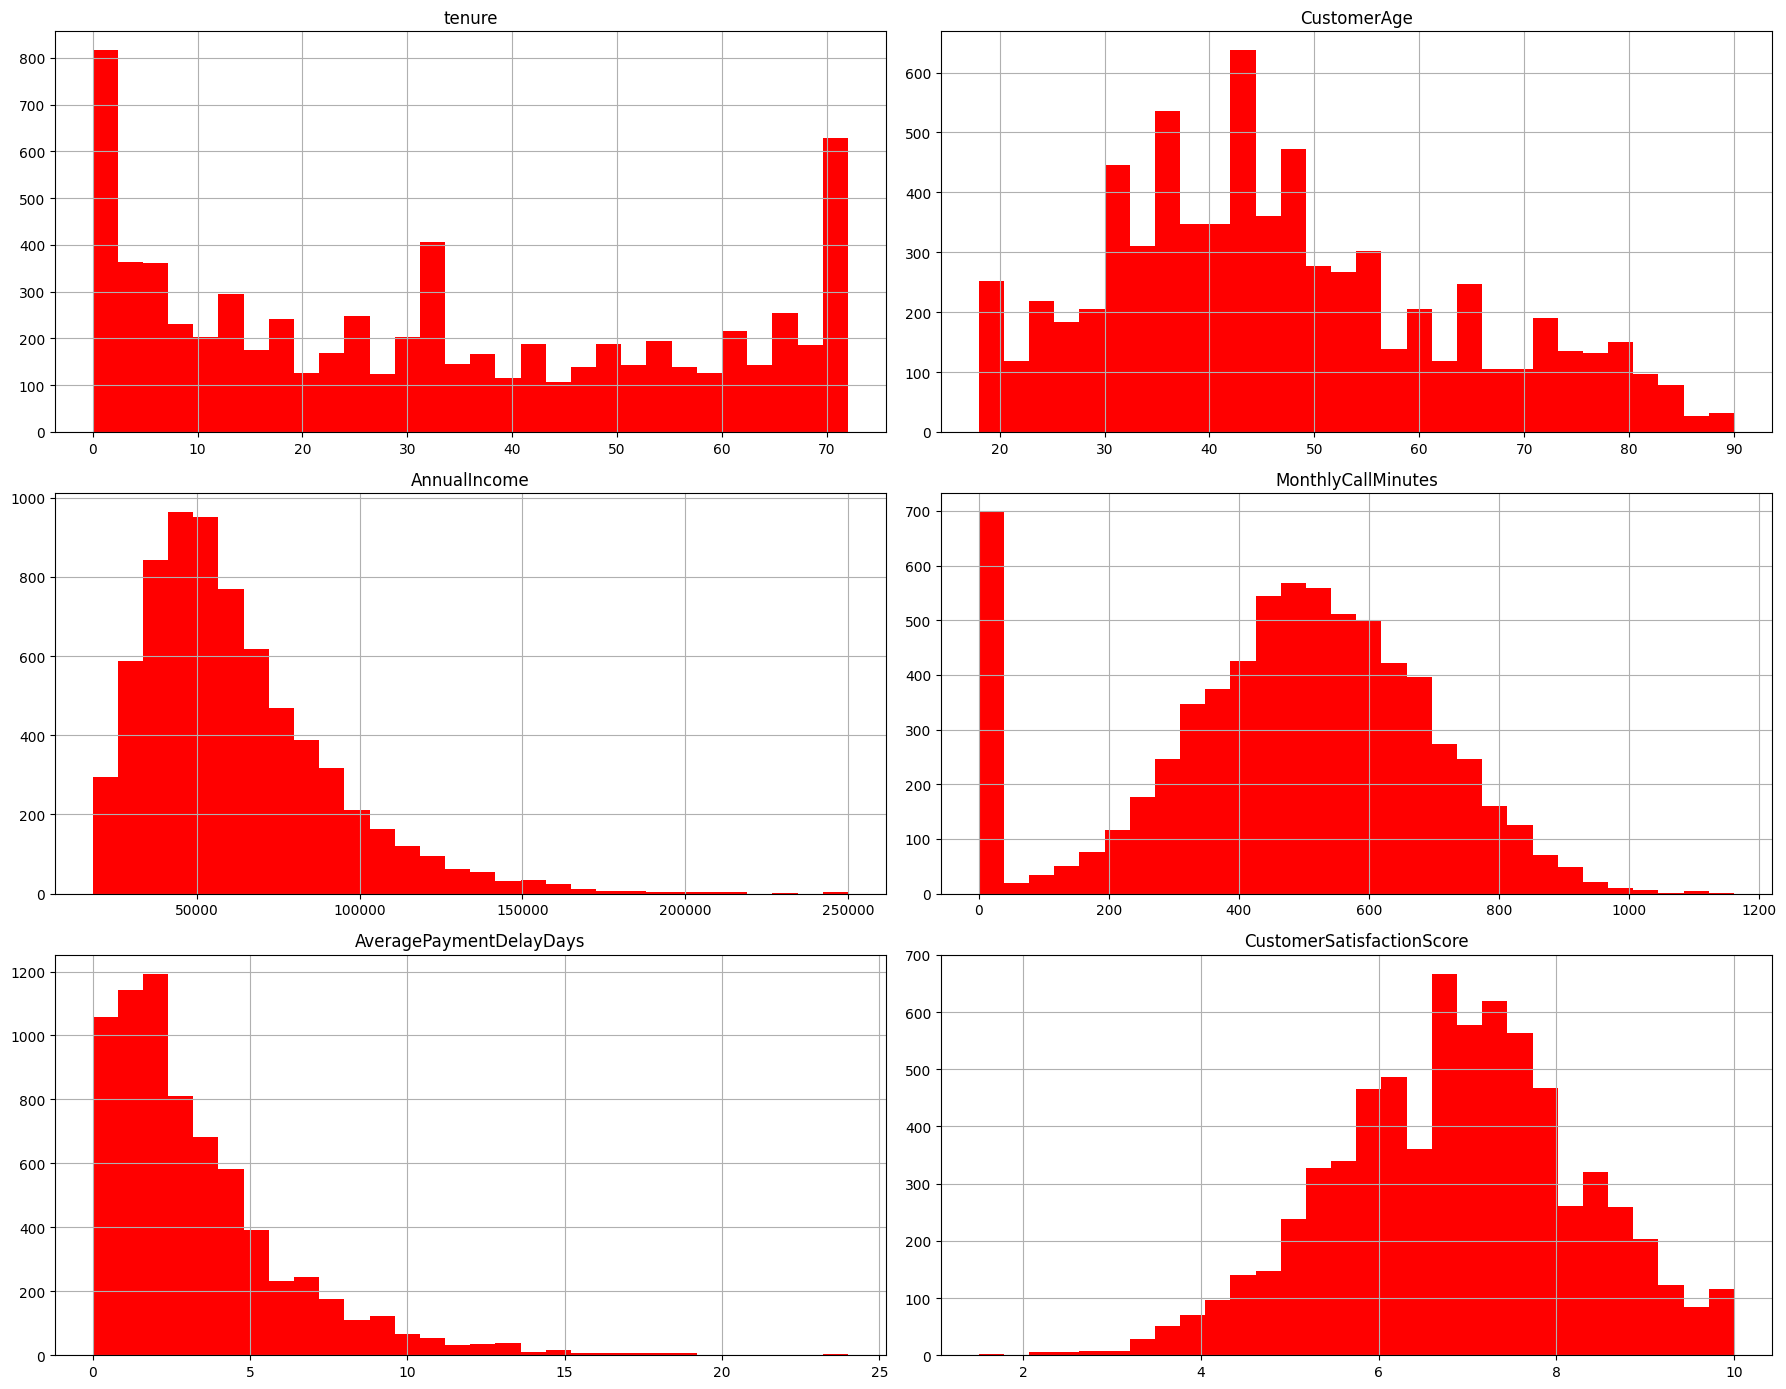

In [ ]:
# Create histograms for all of the numeric columns to check for skewness
df.hist(bins = 30, figsize = (18, 14), color = 'red')
plt.tight_layout()
plt.show()

From our histograms we see that numeric variables AnnualIncome and AveragePaymentDelayDays. The rest of the numeric variables have a normal distribution.

In [ ]:
df['Log_AnnualIncome'] = np.log1p(df['AnnualIncome'])
df['Log_AveragePaymentDelayDays'] = np.log1p(df['AveragePaymentDelayDays'])
df = df.drop(columns=['AnnualIncome', 'AveragePaymentDelayDays'])

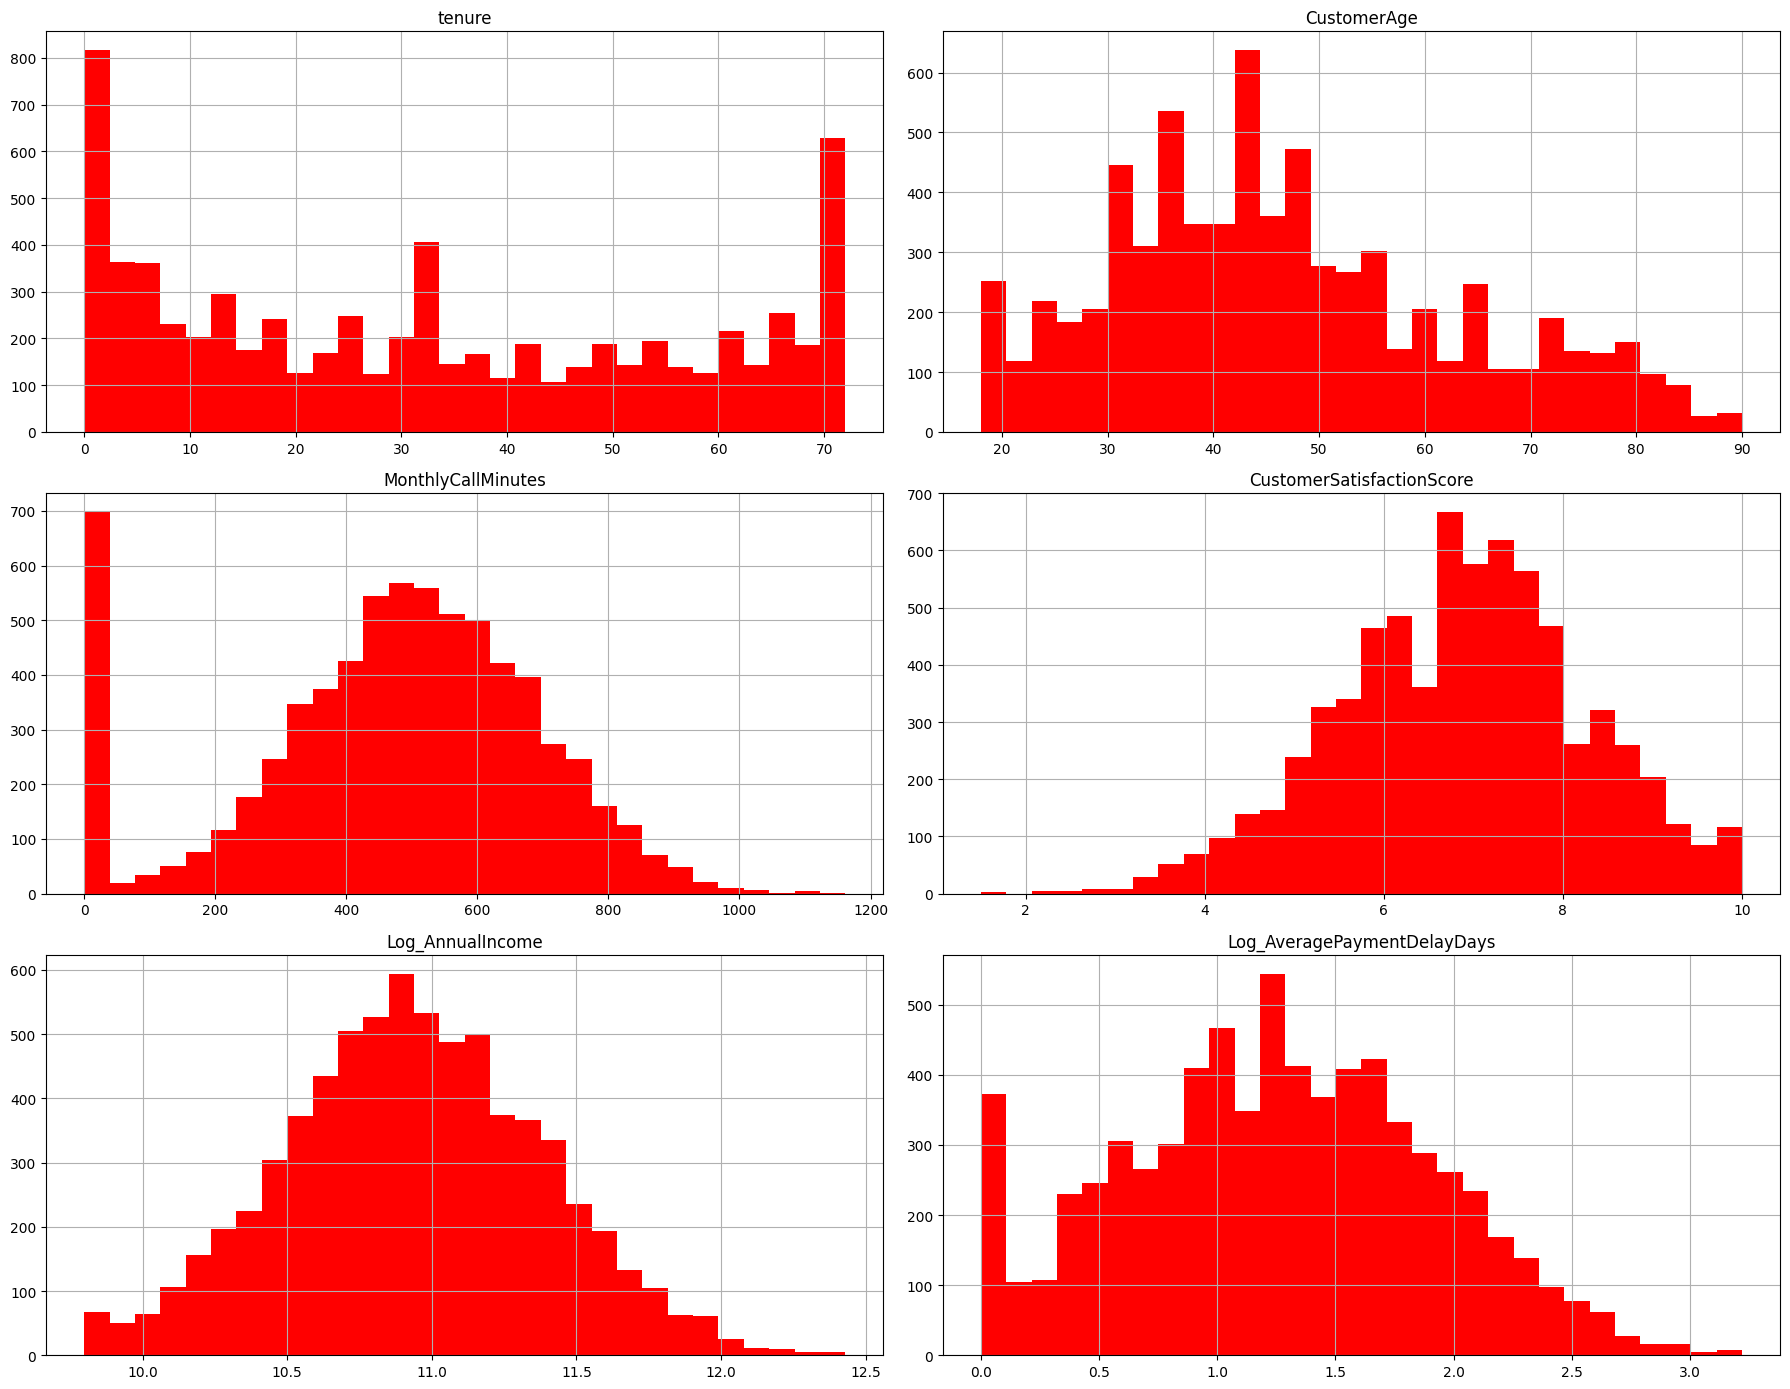

In [ ]:
# Create histograms for all of the numeric columns to check for skewness
df.hist(bins = 30, figsize = (18, 14), color = 'red')
plt.tight_layout()
plt.show()

To address the skewness identified in our numeric distribution plots, we applied a natural log transformation to both AnnualIncome and AveragePaymentDelayDays to reduced the influence of extreme values. This compresses extremely high values and pulls outliers closer to the mean, resulting in a more symmetric, bell-shaped distribution. After creating these new, normalized features, we dropped the original AnnualIncome and AveragePaymentDelayDays columns to prevent data redundancy and collinearity.

**Checking for Outliers using Boxplots**

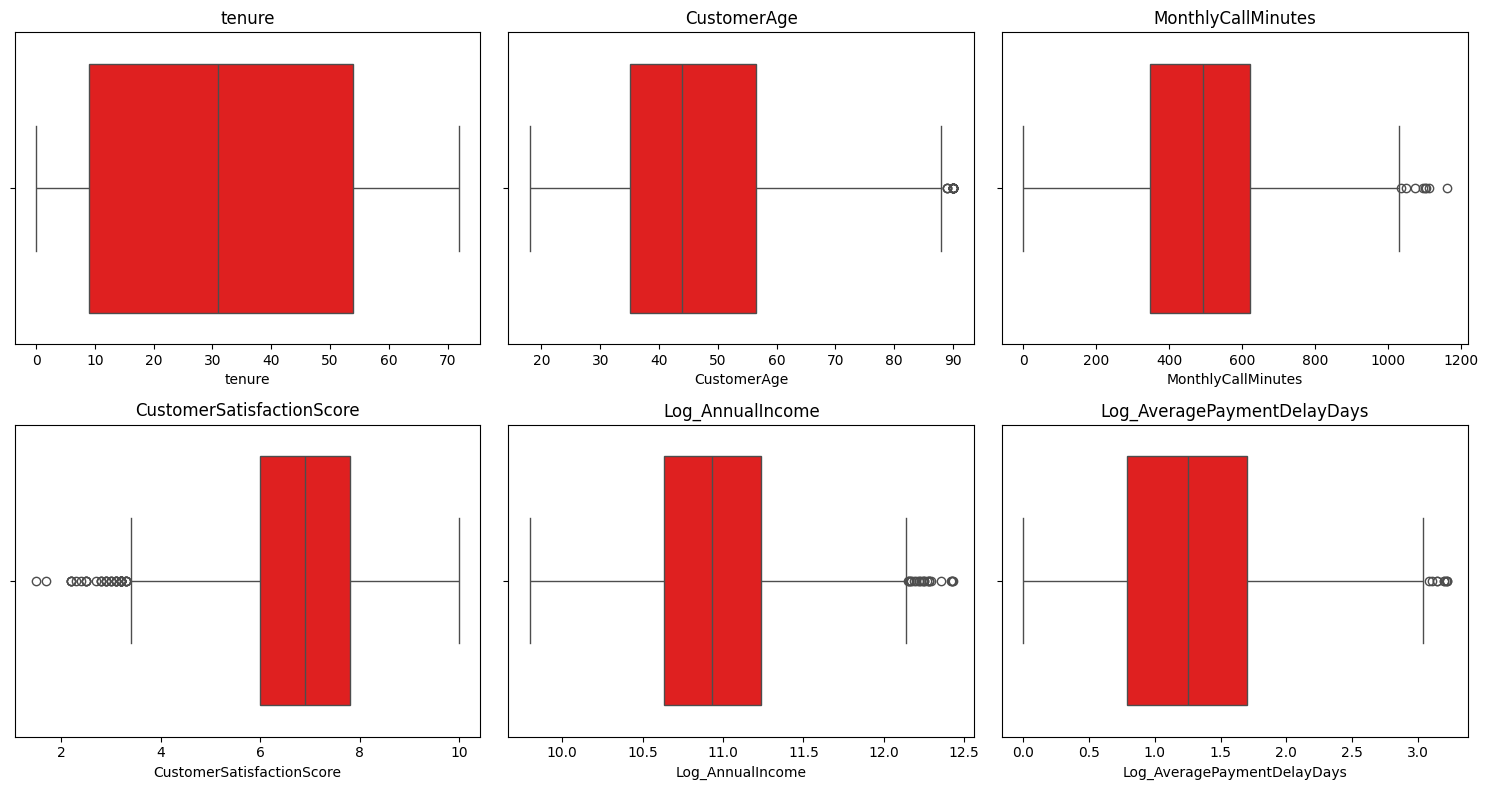

In [ ]:
num_cols = ['tenure', 'CustomerAge', 'MonthlyCallMinutes',
            'CustomerSatisfactionScore', 'Log_AnnualIncome',
            'Log_AveragePaymentDelayDays']

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flatten(), num_cols):
    sns.boxplot(x=df[col], ax=ax, color='red')
    ax.set_title(col)
plt.tight_layout()
plt.show()

When looking at the boxplots, you can see that several of the continuous variables do have outliers, such as CustomerAge, MonthlyCallMinutes, CustomerSatisfactionScore, Log_AnnualIncome, and Log_AveragePaymentDelayDays. However, even though they do have outliers, they should not be removed because in each variable it does make some sense that there would be values outside of the normal range.

**Create Dummy Variables for all the categorical variables**

In [ ]:
# drop customerID from the table
df = df.drop(columns=['customerID'])
df.head()

,gender,SeniorCitizen,tenure,PhoneService,MultipleLines,InternetService,TechSupport,Contract,PaperlessBilling,PaymentMethod,CustomerAge,MonthlyCallMinutes,CustomerSatisfactionScore,Churn,Log_AnnualIncome,Log_AveragePaymentDelayDays
0,Female,No,1.0,No,Yes,DSL,No,Month-to-month,No,Electronic check,77.0,0.0,6.0,No,10.581749,2.517696
1,Male,No,34.0,Yes,No,DSL,No,One year,Yes,Mailed check,22.0,375.1,6.6,No,11.535597,0.405465
2,Male,No,2.0,Yes,No phone service,DSL,No,Month-to-month,Yes,Mailed check,43.0,373.6,6.2,Yes,10.198766,1.481605
3,Male,No,45.0,No,Yes,DSL,Yes,One year,Yes,Missing,71.0,0.0,6.8,No,11.413834,0.875469
4,Female,No,2.0,Yes,No,Fiber optic,No,Month-to-month,Yes,Electronic check,44.0,221.7,6.3,Yes,11.332734,1.916923


In [ ]:
df_eda = df.copy()
df_eda['ChurnFlag'] = (df_eda['Churn'] == 'Yes').astype(int)
df_eda['AveragePaymentDelayDays'] = np.expm1(df_eda['Log_AveragePaymentDelayDays'])

print(f"Overall churn rate: {df_eda['ChurnFlag'].mean():.1%}")

Overall churn rate: 26.5%


In [ ]:
df['Churn'].value_counts()
y = df.pop('Churn').map({'Yes':1, 'No': 0})

**Add dummy variables**

In [ ]:
# One hot encode all of the categorical variables
df = pd.get_dummies(df, drop_first = True, dtype=int)
X = df
df.head()

,tenure,CustomerAge,MonthlyCallMinutes,CustomerSatisfactionScore,Log_AnnualIncome,Log_AveragePaymentDelayDays,gender_Male,SeniorCitizen_Yes,PhoneService_Yes,MultipleLines_No phone service,...,InternetService_No,TechSupport_No internet service,TechSupport_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,PaymentMethod_Missing
0,1.0,77.0,0.0,6.0,10.581749,2.517696,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
1,34.0,22.0,375.1,6.6,11.535597,0.405465,1,0,1,0,...,0,0,0,1,0,1,0,0,1,0
2,2.0,43.0,373.6,6.2,10.198766,1.481605,1,0,1,1,...,0,0,0,0,0,1,0,0,1,0
3,45.0,71.0,0.0,6.8,11.413834,0.875469,1,0,0,0,...,0,0,1,1,0,1,0,0,0,1
4,2.0,44.0,221.7,6.3,11.332734,1.916923,0,0,1,0,...,0,0,0,0,0,1,0,1,0,0


In [ ]:
df.isna().sum()

,0
tenure,0
CustomerAge,0
MonthlyCallMinutes,0
CustomerSatisfactionScore,0
Log_AnnualIncome,0
Log_AveragePaymentDelayDays,0
gender_Male,0
SeniorCitizen_Yes,0
PhoneService_Yes,0
MultipleLines_No phone service,0


All remaining categorical predictors were converted into numeric dummy columns using one-hot encoding with pd.get_dummies() to prevent dummy variable trap multicollinearity. Finally, a correlation heatmap was plotted to visualize linear relationships between all engineered features and identify any potential collinearity issues.

**Correlation Matrix**

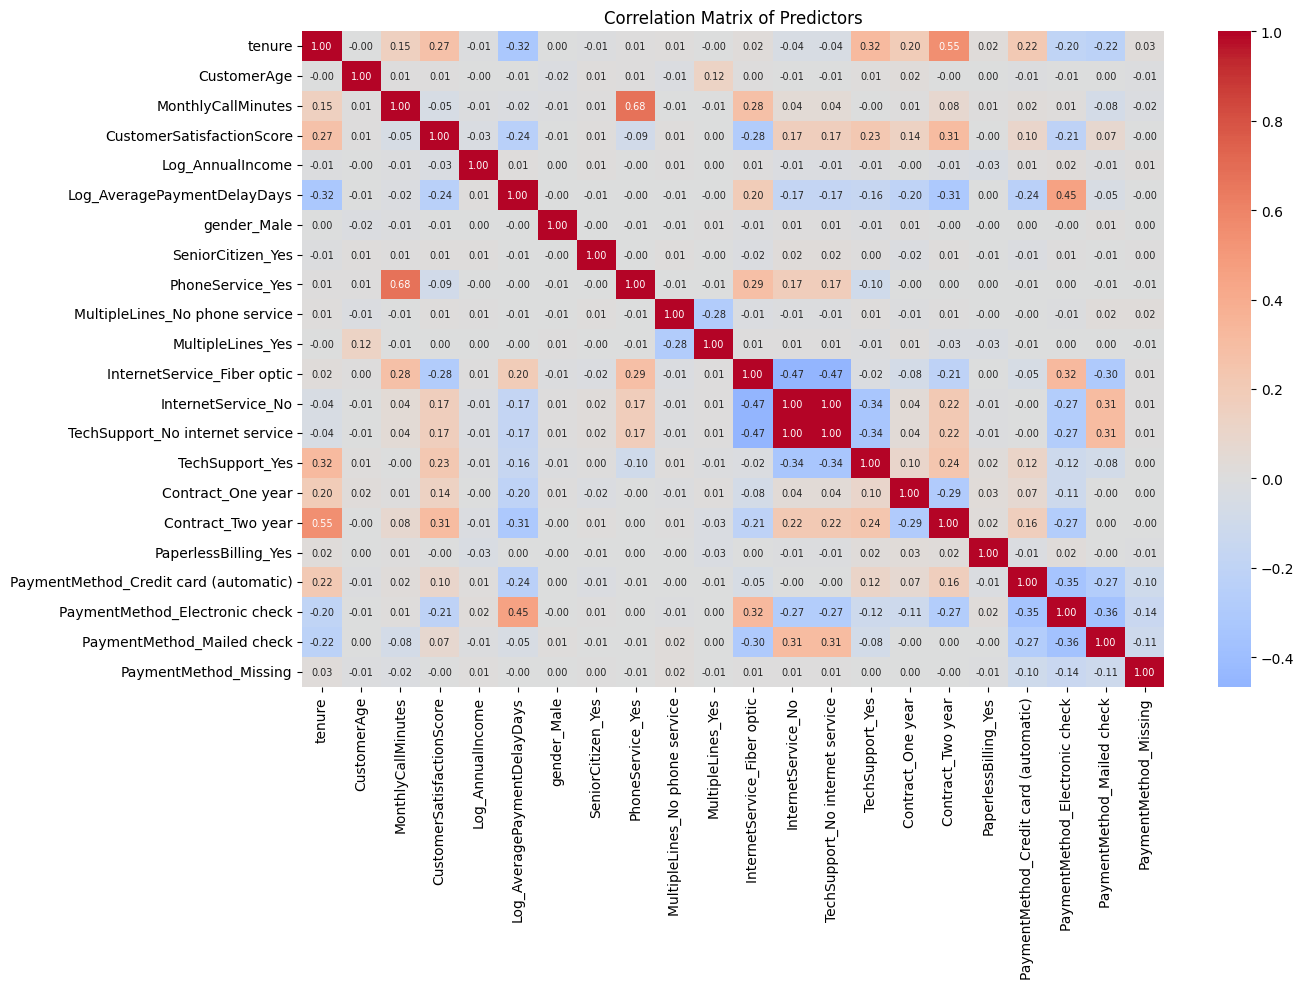

In [ ]:
plt.figure(figsize=(14, 10))
sns.heatmap(df.corr(), cmap='coolwarm', center=0, annot=True, fmt='.2f', annot_kws={'size': 7})
plt.title('Correlation Matrix of Predictors')
plt.tight_layout()
plt.show()

In [ ]:
# InternetService_No and TechSupport_No internet service are identical (correlation = 1.0)
# Drop one to remove perfect multicollinearity
df = df.drop(columns=['TechSupport_No internet service'])
X = df

The correlation matrix shows one pair of perfectly correlated predictors. InternetService_No and TechSupport_No internet service (1.00). These columns are identical because any customer without internet service is automatically recorded as having “No internet service” for tech support. Since they contain the same information, we dropped TechSupport_No internet service to avoid perfect multicollinearity. Aside from this pair, the correlation matrix shows no pairs of predictors with correlations above 0.7, indicating no serious multicollinearity, so we kept all the variables. The strongest relationship is between MonthlyCallMinutes and PhoneService_Yes (0.68), which makes sense since customers without phone service have few or no call minutes. Tenure is also moderately correlated with two-year contracts (0.55), reflecting that longer-term customers tend to commit to longer contracts.


**Final Data Cleaning Summary**


The original dataset contained 7,043 observations and 17 variables. We examined the data for duplicate records, missing values, skewness, and potential outliers. No completely duplicated observations were found. Missing values were addressed using mean imputation, median imputation, and a separate missing category for PaymentMethod. Logarithmic transformations were applied to AnnualIncome and AveragePaymentDelayDays to address skewness, while potential outliers were retained because they may represent meaningful customer characteristics. We removed customerID because it is an identifier rather than a predictor and converted categorical variables into numeric dummy variables. Finally, we examined correlations between predictors to identify potential multicollinearity. These steps prepared the dataset for the next phase of predictive modeling.

# **Research Questions**

1. How does contract type affect churn?
2. Is customer satisfaction score associated with churn, and how strongly?
3. Do customers who pay late churn more often than customers who pay on time?




#### **Association Matrix of Original Predictors with Churn**

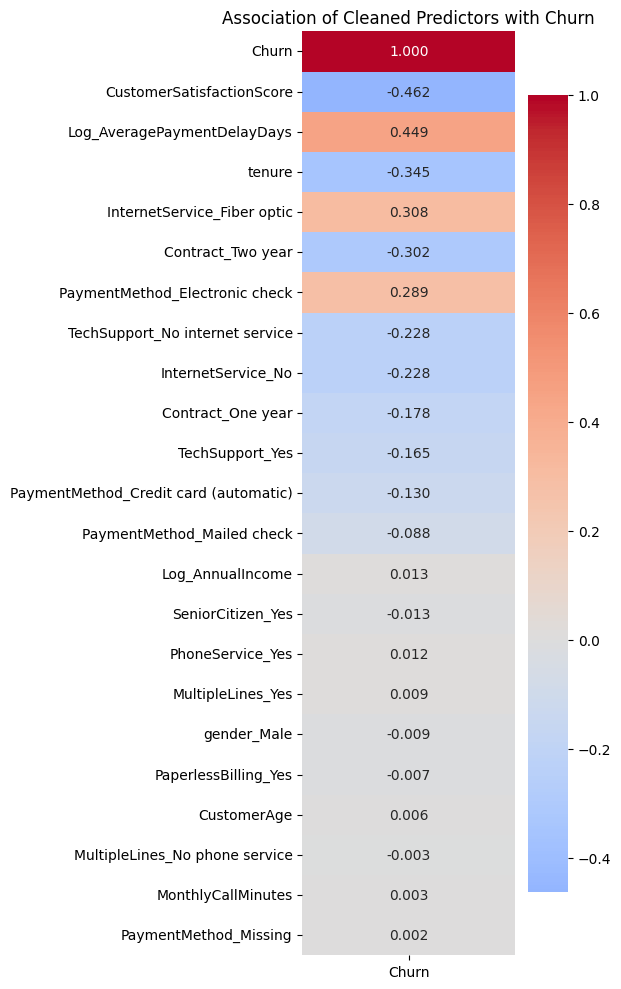

,Churn
Churn,1.000000
CustomerSatisfactionScore,-0.462027
Log_AveragePaymentDelayDays,0.448943
tenure,-0.344802
InternetService_Fiber optic,0.308020
Contract_Two year,-0.302253
PaymentMethod_Electronic check,0.288817
TechSupport_No internet service,-0.227890
InternetService_No,-0.227890
Contract_One year,-0.177820


In [ ]:
# Combine original numeric/encoded features in df with the Churn target y
original_association_df = df.copy()
original_association_df['Churn'] = y

# Calculate correlation matrix for numeric columns
corr_matrix_orig = original_association_df.select_dtypes(include=[np.number]).corr()

# Extract and sort correlations specifically with Churn by absolute value
churn_associations_orig = corr_matrix_orig[['Churn']].sort_values(by='Churn', key=abs, ascending=False)

# Plot the associations
plt.figure(figsize=(6, 10))
sns.heatmap(churn_associations_orig, annot=True, cmap='coolwarm', fmt='.3f', cbar=True, center=0)
plt.title('Association of Cleaned Predictors with Churn')
plt.tight_layout()
plt.show()

display(churn_associations_orig)

The association matrix shows the strength and the direction between different customer characteristics and customer churn, which helps to identify which factors are most strongly associated with customers leaving. From the matrix, it shows Customer Satisfaction Score and Average Payment Delay Days are most strongly associated with higher Customer Satisfaction Scores being less likely to churn and customers with longer payment delay days more likely to churn.

### **Fit a Logistic Regression Model**
We will split our data into training and testing sets (80/20 split), scale the features, train a logistic regression model, and evaluate its performance.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# Split the dataset into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=52, stratify=y)

# Scale continuous numerical features to ensure proper convergence and interpretation
scaler = StandardScaler()

# Fit the scaler on the training set and transform both training and test sets
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Fit the Logistic Regression model
log_reg = LogisticRegression(random_state=52, max_iter=1000)
log_reg.fit(X_train_scaled, y_train)

# Make predictions on the test set
y_pred = log_reg.predict(X_test_scaled)
y_pred_proba = log_reg.predict_proba(X_test_scaled)[:, 1]

# Evaluate the model
print("Accuracy Score:", accuracy_score(y_test, y_pred))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

Accuracy Score: 0.8410220014194464

Confusion Matrix:
 [[945  90]
 [134 240]]

Classification Report:
               precision    recall  f1-score   support

           0       0.88      0.91      0.89      1035
           1       0.73      0.64      0.68       374

    accuracy                           0.84      1409
   macro avg       0.80      0.78      0.79      1409
weighted avg       0.84      0.84      0.84      1409



Our logistic regression model achieved an accuracy of 84.1%, meaning it correctly predicted whether customers would churn or stay approximately 84% of the time. The model performed better at identifying customers who stayed (91% recall) compared to customers who churned (64% recall). Although the model correctly identified 240 customers who churned, it failed to identify 134, suggesting there is room for improvement in predicting at-risk customers.

### **Model Coefficients**
Let's analyze the impact of each feature on churn by plotting the coefficients.

/tmp/ipykernel_41534/1436461471.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Coefficient', y='Feature', data=coef_df, palette='coolwarm')


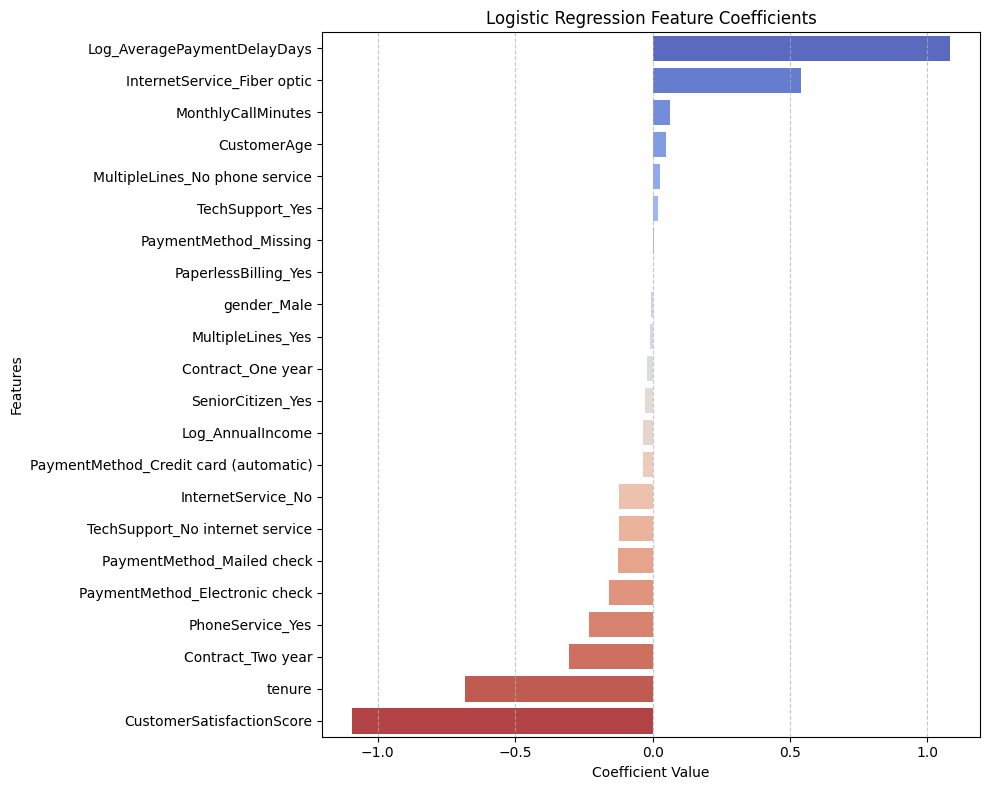

,Feature,Coefficient
5,Log_AveragePaymentDelayDays,1.082583
11,InternetService_Fiber optic,0.539721
2,MonthlyCallMinutes,0.062009
1,CustomerAge,0.049759
9,MultipleLines_No phone service,0.027608
14,TechSupport_Yes,0.018142
21,PaymentMethod_Missing,0.006391
17,PaperlessBilling_Yes,0.000224
6,gender_Male,-0.006116
10,MultipleLines_Yes,-0.007669


In [ ]:
# Create a DataFrame of features and their corresponding coefficients
coef_df = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': log_reg.coef_[0]
}).sort_values(by='Coefficient', ascending=False)

# Plot the coefficients
plt.figure(figsize=(10, 8))
sns.barplot(x='Coefficient', y='Feature', data=coef_df, palette='coolwarm')
plt.title('Logistic Regression Feature Coefficients')
plt.xlabel('Coefficient Value')
plt.ylabel('Features')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

display(coef_df)

We can see that CustomerSatisfactionScore	(-1.094167),
Log_AveragePaymentDelayDays (1.083), tenure	(-0.683696), InternetService_Fiber optic (0.539721) are all important indicators that are associated with churn. As the positive coeiffcients increase the probability of churn increases, as the negative coeifficents increase the probaility of churn decreases.

In [ ]:
coef_df['OddsRatio'] = np.exp(coef_df['Coefficient'])
display(coef_df[coef_df['Feature'].isin(['Contract_One year', 'Contract_Two year',
        'CustomerSatisfactionScore', 'Log_AveragePaymentDelayDays'])])

,Feature,Coefficient,OddsRatio
5,Log_AveragePaymentDelayDays,1.082583,2.952295
15,Contract_One year,-0.020618,0.979593
16,Contract_Two year,-0.304291,0.737646
3,CustomerSatisfactionScore,-1.094167,0.334818


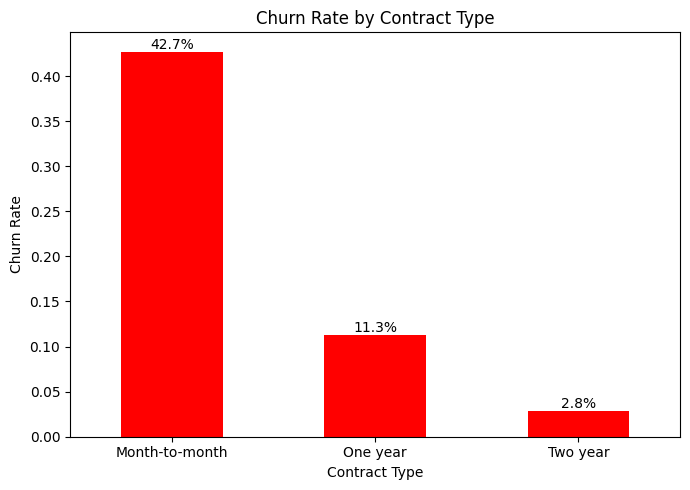

In [ ]:
# RQ1: Contract type
contract_rate = df_eda.groupby('Contract')['ChurnFlag'].mean()

plt.figure(figsize=(7, 5))
ax = contract_rate.plot(kind='bar', color='red')
ax.bar_label(ax.containers[0], labels=[f'{v:.1%}' for v in contract_rate])
plt.title('Churn Rate by Contract Type')
plt.xlabel('Contract Type')
plt.ylabel('Churn Rate')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

From the histogram, you can see that churn rate varies by contract type. Month-to-month customers churn at 42.7%, about four times the rate of one-year customers (11.3%) and fifteen times the rate of two-year customers (2.8%). This suggests that longer contracts are strongly associated with customer retention, likely because customers who commit to longer terms are more invested in the service and face a higher barrier to leaving. For the business, month-to-month customers represent the highest-risk group, and incentives to move them onto longer contracts could be an effective retention strategy.

Based on the logistic regression, two-year contracts still lower the odds of churn after controlling for other variables (odds ratio 0.74), but the one-year effect is near zero (0.98), suggesting part of the contract type’s effect overlaps with tenure and satisfaction.

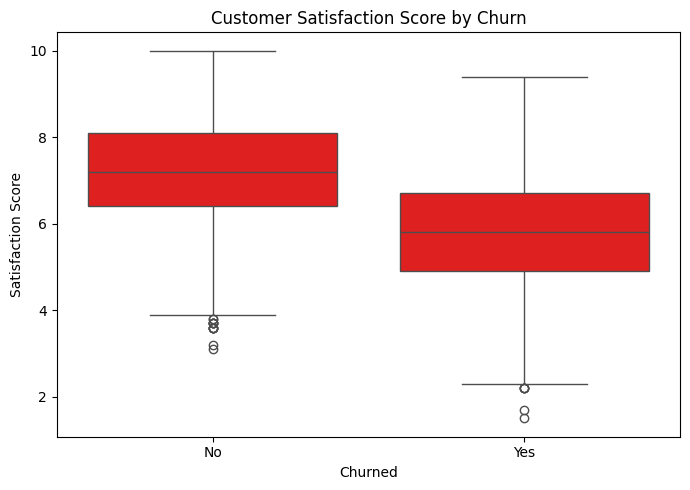

,MedianSatisfaction
Churn,
No,7.2
Yes,5.8


In [ ]:
# RQ2: Customer satisfaction
plt.figure(figsize=(7, 5))
sns.boxplot(x='Churn', y='CustomerSatisfactionScore', data=df_eda, color='red', order=['No', 'Yes'])
plt.title('Customer Satisfaction Score by Churn')
plt.xlabel('Churned')
plt.ylabel('Satisfaction Score')
plt.tight_layout()
plt.show()

display(df_eda.groupby('Churn')['CustomerSatisfactionScore'].median().to_frame('MedianSatisfaction'))

Customers who churned reported noticeably lower satisfaction scores than those who stayed, with a median score of 5.8 compared to 7.2. The boxplots show that the entire distribution for churned customers sits lower, not just the middle, which indicates that dissatisfaction is a consistent pattern among customers who leave.

The logistic regression supports this. Customer satisfaction has a coefficient of -1.09 and an odds ratio of 0.33, meaning that each one-standard-deviation increase in satisfaction (about 1.4 points) cuts a customer’s odds of churning by roughly 67%, holding all other variables constant. This suggests that tracking satisfaction scores could help the company identify at-risk customers before they churn and intervene with targeted outreach.

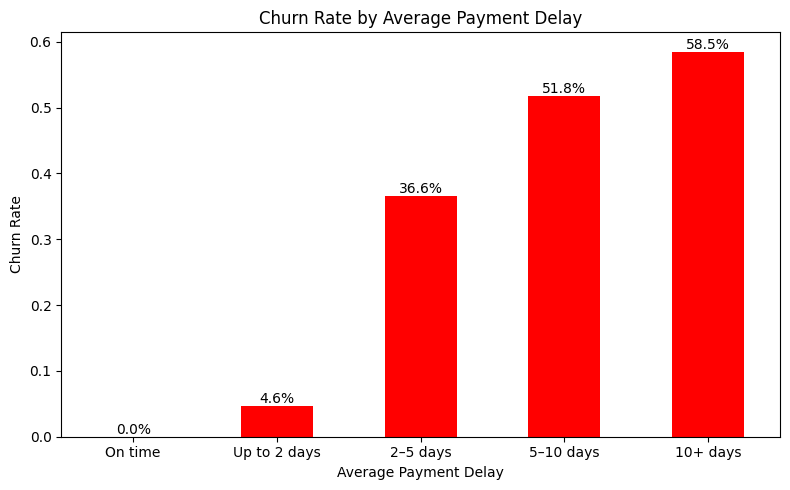

In [ ]:
# RQ3: Payment delay
df_eda['DelayBucket'] = pd.cut(df_eda['AveragePaymentDelayDays'], bins=[-1, 0, 2, 5, 10, 100],
                               labels=['On time', 'Up to 2 days', '2–5 days', '5–10 days', '10+ days'])
delay_rate = df_eda.groupby('DelayBucket', observed=True)['ChurnFlag'].mean()

plt.figure(figsize=(8, 5))
ax = delay_rate.plot(kind='bar', color='red')
ax.bar_label(ax.containers[0], labels=[f'{v:.1%}' for v in delay_rate])
plt.title('Churn Rate by Average Payment Delay')
plt.xlabel('Average Payment Delay')
plt.ylabel('Churn Rate')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Churn rises steadily as customers pay later. None of the customers who paid on time churned, compared to 4.0% of those up to 2 days late, 35.9% of those 2–5 days late, 51.8% of those 5–10 days late, and 58.5% of those more than 10 days late. The largest jump occurs between 2 and 5 days late, suggesting this may be a realistic threshold for flagging customers. Late payment may be an indicator of the customer having financial issues, making it a sort of early warning sign that the company could act on before a customer churns.
The logistic regression supports this. Log payment delay has the largest positive coefficient (1.08, with an odds ratio of 2.95), meaning a one standard deviation increase in payment delay roughly triples the odds of churning, holding other variables constant.

#### **Final Conclusion**

Our insights and recommendations from this analysis is to focus retention efforts on month-to-month customers, and offer incentives to move them onto longer contracts. Additionally, we recommend Monitor customer satisfaction scores and reach out to customers whose scores drop. Lastly we recommend treating late payments, especially beyond two days, as an early warning sign that triggers retention outreach.


 The limitations from this analysis is these findings show association, not causation. The dataset does not include revenue or billing information, so we could not identify which customer segments are most valuable or estimate the financial impact of churn. Future work could add revenue data and test more advanced models to improve recall for churned customers.



In [ ]:
#@title Convert ipynb to HTML in Colab
# Upload ipynb
from google.colab import files
f = files.upload()

# Convert ipynb to html
import subprocess
file0 = list(f.keys())[0]
_ = subprocess.run(["pip", "install", "nbconvert"])
_ = subprocess.run(["jupyter", "nbconvert", file0, "--to", "html"])

# download the html
files.download(file0[:-5]+"html")

Saving ChurnProjectPreprocess.ipynb to ChurnProjectPreprocess.ipynb


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>